# A differentiable surrogate likelihood

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `ebd964ed89e4`](https://github.com/OJWatson/metis/tree/ebd964ed89e468e4f03197f2c0217c581e294b97).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("ebd964ed89e468e4f03197f2c0217c581e294b97")


An iTARFlow model can evaluate $\log p(y\mid\theta)$ and differentiate it with
respect to simulator inputs $\theta$. That is the link to parameter-fitting
methods such as MCMC or variational inference.

This notebook fits a small synthetic example, plots its learned likelihood and
calculates a gradient. It does not fit a posterior.

## Train on simulated responses

Our simulator has six time points: $y(t)=\theta(1+t)+\epsilon_t$, with independent
$\epsilon_t\sim N(0,0.1^2)$. We simulate three replicates at each of 40 parameter
settings, then hold out complete settings for validation and testing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from metis import SimulationDataset, Surrogate, TrainingConfig

rng = np.random.default_rng(7)
times = np.arange(6, dtype=float)
inputs = np.repeat(np.linspace(0.1, 0.9, 40)[:, None], 3, axis=0)
outputs = inputs[:, None, :] * (1 + times[None, :, None])
outputs = outputs + rng.normal(0, 0.1, outputs.shape)
bank = SimulationDataset.from_arrays(
    inputs, outputs, input_names=["theta"], output_names=["response"], times=times,
)
split = bank.split(seed=42)
model = Surrogate("itarflow", model_options={
    "channels": 32, "num_layers": 1, "num_blocks": 2, "num_heads": 2,
}).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=300, batch_size=32, eval_every=50, seed=42),
)

## Inspect the likelihood

Take one held-out trajectory and evaluate its density at a range of candidate
inputs. In this synthetic example we also know the simulator's Gaussian density,
so we can compare the two curves directly.

In [2]:
observation = split.test.outputs[:1]
true_theta = float(split.test.inputs[0, 0])
candidates = np.linspace(split.train.inputs.min(), split.train.inputs.max(), 200)
repeated_observation = np.repeat(observation, len(candidates), axis=0)
learned = model.log_prob(candidates[:, None], repeated_observation)
residual = observation[0, :, 0] - candidates[:, None] * (1 + times)
known = -0.5 * np.sum((residual / 0.1) ** 2 + np.log(2 * np.pi * 0.1**2), axis=1)

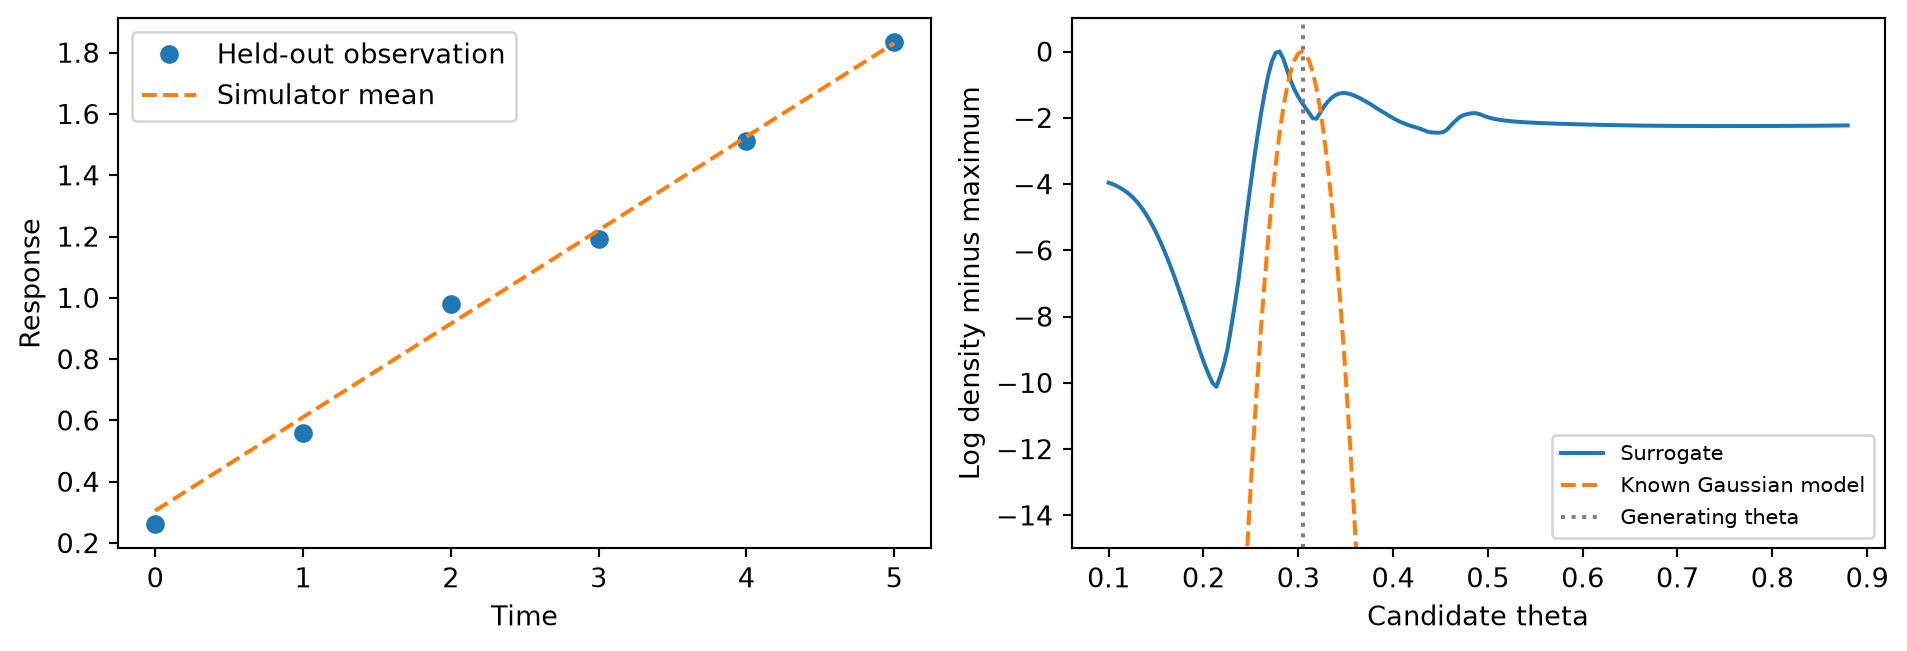

In [3]:
#| code-fold: true
#| code-summary: "Plot the observation and likelihood curves"
#| fig-cap: "iTARFlow trained on the synthetic Gaussian-response bank. Both log-density curves are shifted to their own maximum for a shape comparison; these are likelihoods, not posterior distributions."
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(times, observation[0, :, 0], "o", label="Held-out observation")
axes[0].plot(times, true_theta * (1 + times), "--", label="Simulator mean")
axes[0].set(xlabel="Time", ylabel="Response")
axes[0].legend()
axes[1].plot(candidates, learned - learned.max(), label="Surrogate")
axes[1].plot(candidates, known - known.max(), "--", label="Known Gaussian model")
axes[1].axvline(true_theta, color="grey", linestyle=":", label="Generating theta")
axes[1].set(xlabel="Candidate theta", ylabel="Log density minus maximum", ylim=(-15, 1))
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

*iTARFlow trained on the synthetic Gaussian-response bank. Both log-density curves are shifted to their own maximum for a shape comparison; these are likelihoods, not posterior distributions.*

The rendered short fit has a much heavier right tail than the known likelihood.
That would distort parameter inference even though the response trajectories
look plausible. Validate likelihood shape and calibration before using a
surrogate for inference; accurate mean predictions alone are not enough.

## Differentiate in original units

`log_prob_tensor` keeps the computation connected to PyTorch's automatic
differentiation. The saved scalers and the density's change-of-variables
correction are applied internally.

In [4]:
theta = torch.tensor([[true_theta]], dtype=torch.float32, requires_grad=True)
observed = torch.tensor(observation.copy())
log_density = model.log_prob_tensor(theta, observed)
gradient, = torch.autograd.grad(log_density.sum(), theta)
print("Log density:", log_density.detach().tolist())
print("Derivative with respect to theta:", gradient.tolist())

Log density: [0.25125776223480445]
Derivative with respect to theta: [[-41.69636917114258]]


## From likelihood to inference

With observed data $y$ and a separately chosen prior $p(\theta)$, an approximate
posterior would be

$$
p(\theta\mid y)\propto p_{\mathrm{surrogate}}(y\mid\theta)p(\theta).
$$

MCMC samples this target. Variational inference instead fits a tractable
approximation $q_\psi(\theta)$, for example by maximizing

$$
\mathcal L(\psi)=\mathbb E_{q_\psi}\left[
\log p_{\mathrm{surrogate}}(y\mid\theta)+\log p(\theta)-\log q_\psi(\theta)
\right].
$$

The neural weights here are point estimates. Surrogate draws represent learned
simulation variability, not uncertainty in those weights. Real observations,
integer counts or measurement error may need an observation model before this
continuous density is suitable. Keep inference inside the validated input
region, and check identifiability, convergence and posterior predictions.

The [historical VI/MCMC recipe](https://github.com/OJWatson/metis/blob/739d57cdaa5f74b9a0973c527f063eaa3a72ab06/quarto/sbi/vi-mcmc.qmd)
shows a longer application using the former API. See
[migration](https://ojwatson.github.io/metis/package/migration.html) before reusing its checkpoints.